In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import ndimage


import os
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cuda
NVIDIA GeForce RTX 4090


In [4]:
#Import SAM2
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 imported successfully")

SAM2 imported successfully


In [5]:
#Find SAM2 checkpoint
possible_checkpoints = [
    "/home/zahranadeem/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2_repo/checkpoints/sam2_hiera_small.pt",
]

checkpoint = None

for p in possible_checkpoints:
    if os.path.exists(p):
        checkpoint = p
        break

print("Checkpoint:", checkpoint)

assert checkpoint is not None, "SAM2 checkpoint not found"

Checkpoint: /home/zahranadeem/checkpoints/sam2_hiera_small.pt


In [6]:
#Load SAM2 
config = "sam2_hiera_s.yaml"

sam2_model = build_sam2(
    config,
    checkpoint,
    device=device
)

predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 loaded successfully")

SAM2 loaded successfully


In [7]:
#Load VegAnn  and create validation split
dataset = load_dataset("simonMadec/VegAnn")

split_dataset = dataset["train"].train_test_split(
    test_size=0.2,
    seed=42
)

train_dataset = split_dataset["train"]
val_dataset = split_dataset["test"]

print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))

print(val_dataset[0].keys())






Train size: 3020
Validation size: 755
dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [8]:
#Metrics function
def compute_iou_dice(pred_mask, gt_mask):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    iou = intersection / union if union > 0 else 0

    dice = (
        2 * intersection
    ) / (
        pred.sum() + gt.sum()
    ) if (pred.sum() + gt.sum()) > 0 else 0

    return iou, dice

In [32]:
#Auto Vegetation Box function 
def get_vegetation_box_from_image_full(image, padding=0, percentile=60):
    img = image.astype(np.float32) / 255.0
    """
    Automatic vegetation box using Excess Green index.
    Does NOT use GT mask.
    """

    r = img[:, :, 0]
    g = img[:, :, 1]
    b = img[:, :, 2]

    exg = 2 * g - r - b
    threshold = np.percentile(exg, percentile)

    # Inverted version based on debugging
    veg_mask = exg < threshold

    ys, xs = np.where(veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = image.shape[:2]
        return np.array([W//4, H//4, 3*W//4, 3*H//4]), veg_mask

    H, W = image.shape[:2]

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    box = np.array([x1, y1, x2, y2])

    return box, veg_mask

In [33]:
#SAM2 box prompt function 
def run_sam2_box_prompt(image, box):
    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        box=box,
        multimask_output=True
    )

    best_idx = scores.argmax()

    pred_mask = masks[best_idx] > 0

    return pred_mask

In [35]:
#Checking one image 
idx = 0

sample = val_dataset[idx]

image = np.array(sample["image"])
mask = np.array(sample["mask"])

# VegAnn: vegetation = 0, background = 255
gt_mask = mask == 0

auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
    image,
    padding=10,
    percentile=70
)

pred_mask = run_sam2_box_prompt(image, auto_box)

iou, dice = compute_iou_dice(pred_mask, gt_mask)

print("Species:", sample["Species"])
print("Auto box:", auto_box)
print(f"IoU: {iou*100:.2f}%")
print(f"Dice: {dice*100:.2f}%")

Species: Wheat
Auto box: [  0   0 511 511]
IoU: 0.49%
Dice: 0.97%


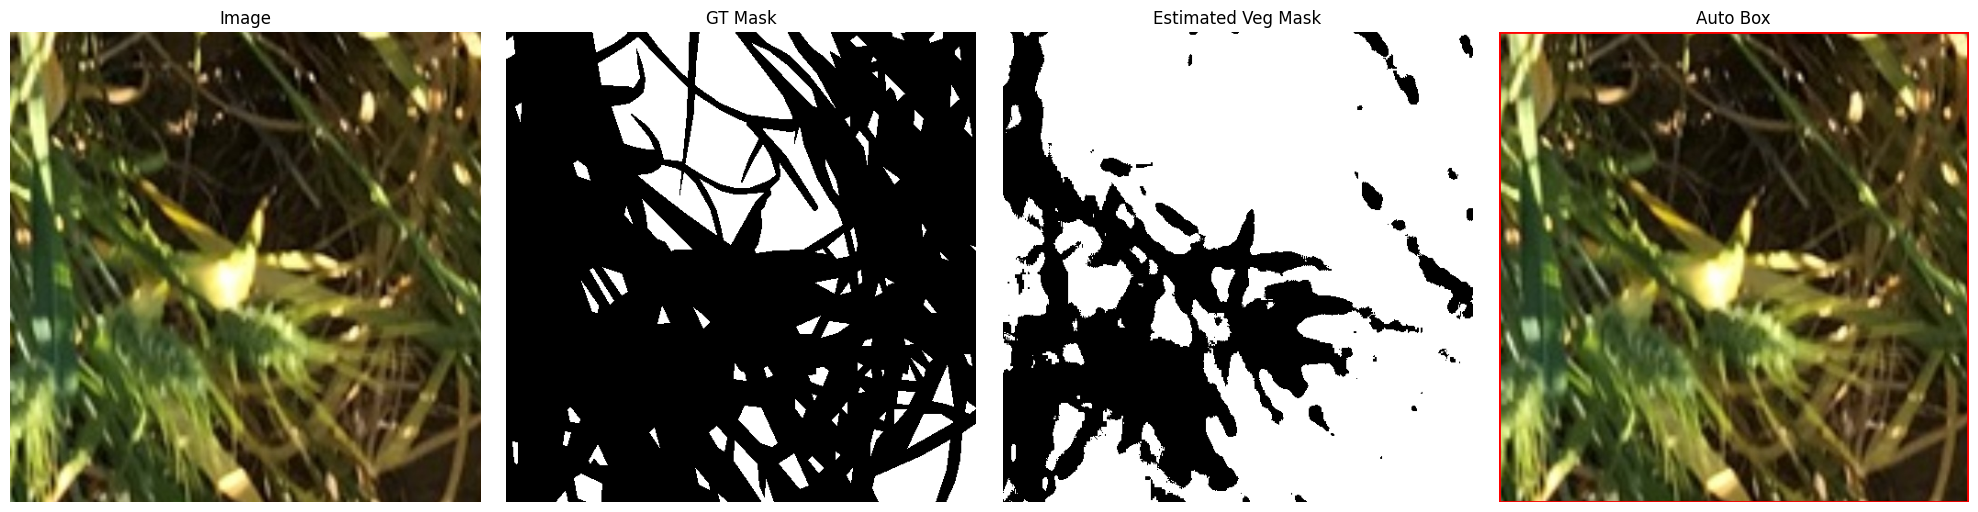

In [36]:
#Visualize 
import matplotlib.patches as patches

x1, y1, x2, y2 = auto_box

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image)
axes[0].set_title("Image")
axes[0].axis("off")

axes[1].imshow(gt_mask, cmap="gray")
axes[1].set_title("GT Mask")
axes[1].axis("off")

axes[2].imshow(estimated_veg_mask, cmap="gray")
axes[2].set_title("Estimated Veg Mask")
axes[2].axis("off")

axes[3].imshow(image)
rect = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)
axes[3].add_patch(rect)
axes[3].set_title("Auto Box")
axes[3].axis("off")

plt.tight_layout()
plt.show()

In [37]:
# Debug SAM2 predictions

predictor.set_image(image)

pos_point = get_positive_point_from_estimated_mask(estimated_veg_mask)
point_labels = np.array([1])

masks, scores, logits = predictor.predict(
    box=auto_box,
    point_coords=pos_point,
    point_labels=point_labels,
    multimask_output=True
)

print("Scores:", scores)
print("Masks shape:", masks.shape)

Scores: [0.18682449 0.6566452  0.56474525]
Masks shape: (3, 512, 512)


In [38]:
#Debugging 
for i in range(len(masks)):

    pred_i = masks[i] > 0

    iou, dice = compute_iou_dice(pred_i, gt_mask)

    iou_inv, dice_inv = compute_iou_dice(~pred_i, gt_mask)

    print(f"\nMask {i}")
    print(f"Score: {scores[i]:.4f}")
    print(f"IoU: {iou*100:.2f}%")
    print(f"Dice: {dice*100:.2f}%")
    print(f"Inverted IoU: {iou_inv*100:.2f}%")
    print(f"Inverted Dice: {dice_inv*100:.2f}%")


Mask 0
Score: 0.1868
IoU: 10.47%
Dice: 18.95%
Inverted IoU: 18.29%
Inverted Dice: 30.92%

Mask 1
Score: 0.6566
IoU: 33.41%
Dice: 50.09%
Inverted IoU: 7.68%
Inverted Dice: 14.27%

Mask 2
Score: 0.5647
IoU: 16.23%
Dice: 27.92%
Inverted IoU: 19.82%
Inverted Dice: 33.08%


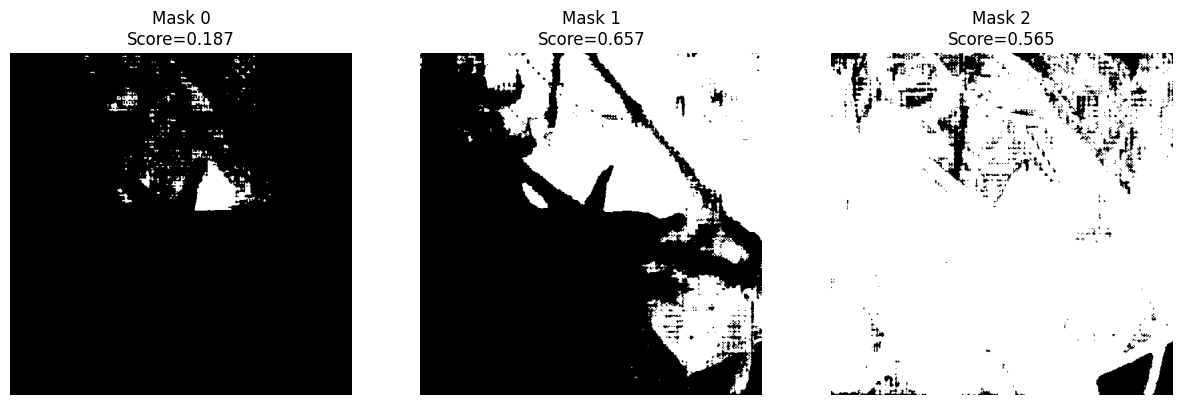

In [39]:
#Debugging
plt.figure(figsize=(15,5))

for i in range(len(masks)):

    plt.subplot(1,3,i+1)

    plt.imshow(masks[i] > 0, cmap="gray")

    plt.title(f"Mask {i}\nScore={scores[i]:.3f}")

    plt.axis("off")

plt.show()

Estimated mask IoU: 29.08881940888739
Estimated mask Dice: 45.06791454455692
Inverted estimated mask IoU: 0.08555809621878645
Inverted estimated mask Dice: 0.17096991383418944


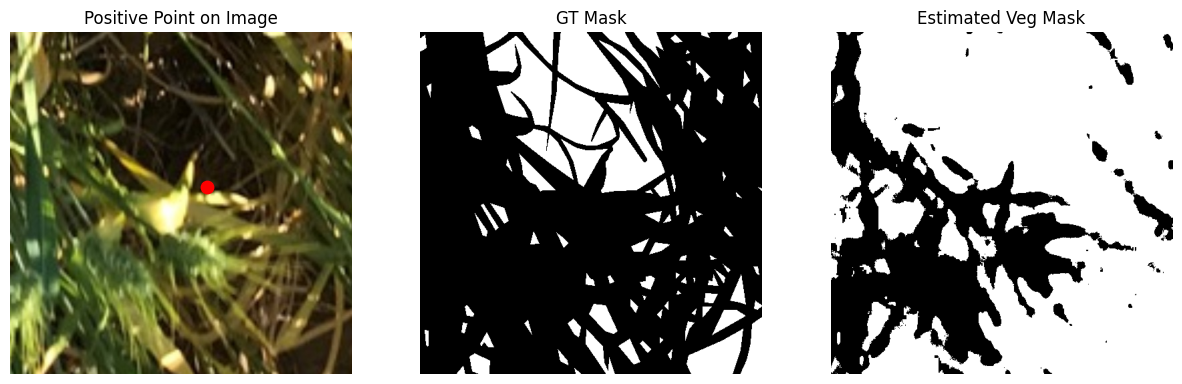

In [40]:
# Check whether estimated vegetation mask is correct

est_iou, est_dice = compute_iou_dice(estimated_veg_mask, gt_mask)
est_inv_iou, est_inv_dice = compute_iou_dice(~estimated_veg_mask, gt_mask)

print("Estimated mask IoU:", est_iou * 100)
print("Estimated mask Dice:", est_dice * 100)

print("Inverted estimated mask IoU:", est_inv_iou * 100)
print("Inverted estimated mask Dice:", est_inv_dice * 100)

pos_point = get_positive_point_from_estimated_mask(estimated_veg_mask)

plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(image)
plt.scatter(pos_point[0][0], pos_point[0][1], c="red", s=80)
plt.title("Positive Point on Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(gt_mask, cmap="gray")
plt.title("GT Mask")
plt.axis("off")

plt.subplot(133)
plt.imshow(estimated_veg_mask, cmap="gray")
plt.title("Estimated Veg Mask")
plt.axis("off")

plt.show()

In [41]:
#Threshold and padding ablation 
ablation_results = []

N = min(100, len(val_dataset))

percentiles = [60, 65, 70, 75, 80]
paddings = [0, 5, 10, 20]

for percentile in percentiles:
    for padding in paddings:

        ious = []
        dices = []

        for idx in tqdm(range(N), desc=f"P{percentile}_Pad{padding}"):

            sample = val_dataset[idx]

            image = np.array(sample["image"])
            mask = np.array(sample["mask"])

            gt_mask = mask == 0

            if gt_mask.sum() == 0:
                continue

            auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
                image,
                padding=padding,
                percentile=percentile
            )

            pred_mask = run_sam2_box_prompt(image, auto_box)

            iou, dice = compute_iou_dice(pred_mask, gt_mask)

            ious.append(iou)
            dices.append(dice)

        ablation_results.append({
            "Percentile": percentile,
            "Padding": padding,
            "Valid Images": len(ious),
            "Mean IoU": np.mean(ious),
            "Mean Dice": np.mean(dices)
        })

ablation_df = pd.DataFrame(ablation_results)

ablation_df

P80_Pad20: 100%|██████████| 100/100 [00:04<00:00, 22.23it/s]


,Percentile,Padding,Valid Images,Mean IoU,Mean Dice
0,60,0,100,0.217685,0.258128
1,60,5,100,0.217685,0.258128
2,60,10,100,0.217685,0.258128
3,60,20,100,0.217685,0.258128
4,65,0,100,0.217685,0.258128
5,65,5,100,0.217685,0.258128
6,65,10,100,0.217685,0.258128
7,65,20,100,0.217685,0.258128
8,70,0,100,0.217685,0.258128
9,70,5,100,0.217685,0.258128


In [42]:
#Generate Table 
ablation_percent = ablation_df.copy()

ablation_percent["Mean IoU"] = ablation_percent["Mean IoU"].apply(
    lambda x: f"{x*100:.2f}%"
)

ablation_percent["Mean Dice"] = ablation_percent["Mean Dice"].apply(
    lambda x: f"{x*100:.2f}%"
)

ablation_percent

,Percentile,Padding,Valid Images,Mean IoU,Mean Dice
0,60,0,100,21.77%,25.81%
1,60,5,100,21.77%,25.81%
2,60,10,100,21.77%,25.81%
3,60,20,100,21.77%,25.81%
4,65,0,100,21.77%,25.81%
5,65,5,100,21.77%,25.81%
6,65,10,100,21.77%,25.81%
7,65,20,100,21.77%,25.81%
8,70,0,100,21.77%,25.81%
9,70,5,100,21.77%,25.81%


In [44]:
#Finding the best setting 
best_row = ablation_df.loc[ablation_df["Mean IoU"].idxmax()]

best_percentile = int(best_row["Percentile"])
best_padding = int(best_row["Padding"])

print("Best setting based on Mean IoU:")
print(best_row)

print()
print("Best percentile:", best_percentile)
print("Best padding:", best_padding)

Best setting based on Mean IoU:
Percentile       60.000000
Padding           0.000000
Valid Images    100.000000
Mean IoU          0.217685
Mean Dice         0.258128
Name: 0, dtype: float64

Best percentile: 60
Best padding: 0


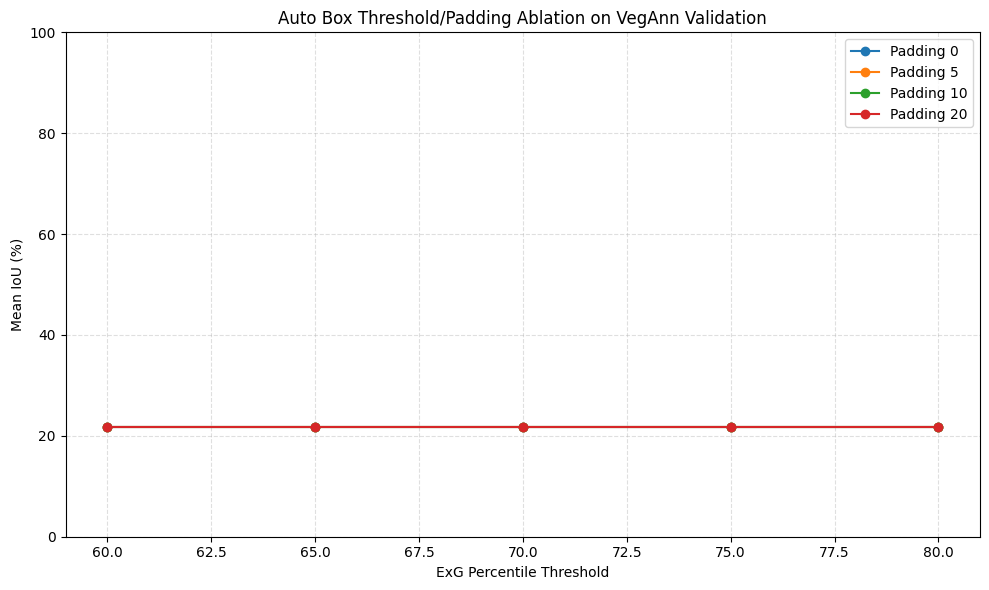

In [45]:
#Plot IoU ablation 
plt.figure(figsize=(10, 6))

for padding in paddings:
    subset = ablation_df[ablation_df["Padding"] == padding]

    plt.plot(
        subset["Percentile"],
        subset["Mean IoU"] * 100,
        marker="o",
        label=f"Padding {padding}"
    )

plt.xlabel("ExG Percentile Threshold")
plt.ylabel("Mean IoU (%)")
plt.title("Auto Box Threshold/Padding Ablation on VegAnn Validation")
plt.ylim(0, 100)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

plt.savefig(
    "auto_box_ablation_iou.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


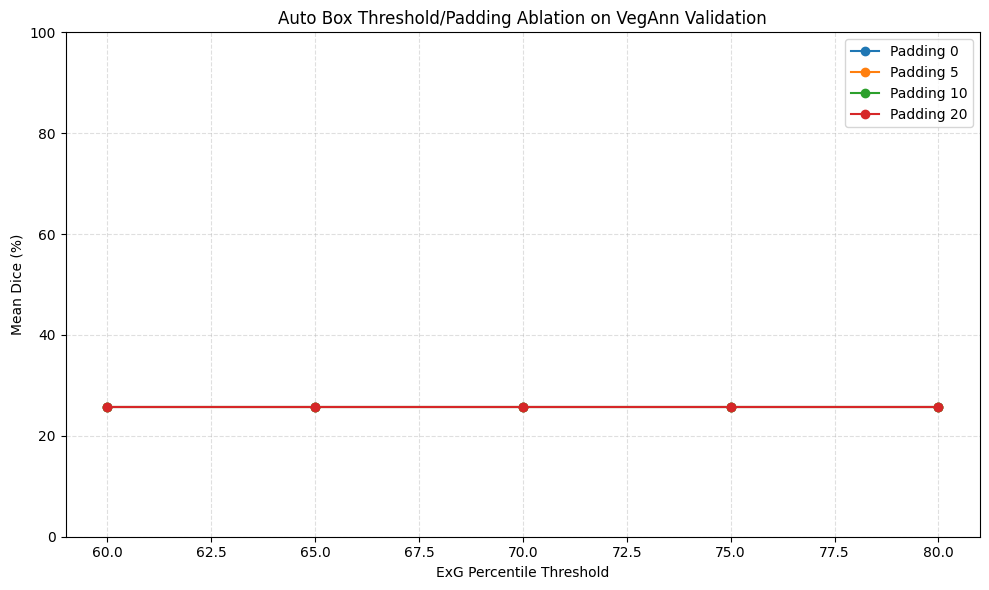

In [46]:
#Plot Dice ablation 
plt.figure(figsize=(10, 6))

for padding in paddings:
    subset = ablation_df[ablation_df["Padding"] == padding]

    plt.plot(
        subset["Percentile"],
        subset["Mean Dice"] * 100,
        marker="o",
        label=f"Padding {padding}"
    )

plt.xlabel("ExG Percentile Threshold")
plt.ylabel("Mean Dice (%)")
plt.title("Auto Box Threshold/Padding Ablation on VegAnn Validation")
plt.ylim(0, 100)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

plt.savefig(
    "auto_box_ablation_dice.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
#SAVE RESULTS 
ablation_df.to_csv(
    "auto_box_ablation_results.csv",
    index=False
)

ablation_percent.to_csv(
    "auto_box_ablation_results_percent.csv",
    index=False
)

print("Saved ablation results.")

Saved ablation results.


In [48]:
#Best setting on 200 images 
N_eval = min(200, len(val_dataset))

ious = []
dices = []

for idx in tqdm(range(N_eval), desc="Best setting evaluation"):

    sample = val_dataset[idx]

    image = np.array(sample["image"])
    mask = np.array(sample["mask"])

    gt_mask = mask == 0

    if gt_mask.sum() == 0:
        continue

    auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
        image,
        padding=best_padding,
        percentile=best_percentile
    )

    pred_mask = run_sam2_box_prompt(image, auto_box)

    iou, dice = compute_iou_dice(pred_mask, gt_mask)

    ious.append(iou)
    dices.append(dice)

print(f"Best setting on {N_eval} images")
print(f"Mean IoU: {np.mean(ious)*100:.2f}%")
print(f"Mean Dice: {np.mean(dices)*100:.2f}%")

Best setting evaluation: 100%|██████████| 200/200 [00:08<00:00, 22.92it/s]

Best setting on 200 images
Mean IoU: 19.44%
Mean Dice: 23.86%


In [20]:
#Positive negatice point helpers
def get_positive_point_from_estimated_mask(estimated_veg_mask):
    ys, xs = np.where(estimated_veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = estimated_veg_mask.shape
        return np.array([[W // 2, H // 2]])

    cx = int(xs.mean())
    cy = int(ys.mean())

    return np.array([[cx, cy]])


def get_negative_point_from_estimated_mask(estimated_veg_mask):
    background_mask = ~estimated_veg_mask

    ys, xs = np.where(background_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = estimated_veg_mask.shape
        return np.array([[0, 0]])

    # choose a background point near top-left-ish area
    return np.array([[int(xs[0]), int(ys[0])]])


def get_three_positive_points_from_estimated_mask(estimated_veg_mask):
    ys, xs = np.where(estimated_veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = estimated_veg_mask.shape
        return np.array([
            [W // 2, H // 2],
            [W // 3, H // 3],
            [2 * W // 3, 2 * H // 3]
        ])

    points = []

    # centroid
    points.append([int(xs.mean()), int(ys.mean())])

    # first quartile-ish point
    q1 = len(xs) // 4
    points.append([int(xs[q1]), int(ys[q1])])

    # third quartile-ish point
    q3 = 3 * len(xs) // 4
    points.append([int(xs[q3]), int(ys[q3])])

    return np.array(points)

In [49]:
#SAM2 box + points function
def run_sam2_box_points_prompt(image, box, point_coords=None, point_labels=None):
    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        box=box,
        point_coords=point_coords,
        point_labels=point_labels,
        multimask_output=True
    )

    best_idx = scores.argmax()

    pred_mask = masks[best_idx] > 0

    return pred_mask

In [50]:
#Pormpt type ablation loop
prompt_ablation_results = []

N = min(200, len(val_dataset))

best_percentile = 60
best_padding = 0

prompt_types = [
    "Box only",
    "Box + 1 positive point",
    "Box + positive + negative point",
    "Box + 3 positive points"
]

for prompt_type in prompt_types:

    ious = []
    dices = []

    for idx in tqdm(range(N), desc=prompt_type):

        sample = val_dataset[idx]

        image = np.array(sample["image"])
        mask = np.array(sample["mask"])

        gt_mask = mask == 0

        if gt_mask.sum() == 0:
            continue

        auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
            image,
            padding=best_padding,
            percentile=best_percentile
        )

        if prompt_type == "Box only":

            pred_mask = run_sam2_box_prompt(
                image,
                auto_box
            )

        elif prompt_type == "Box + 1 positive point":

            pos_point = get_positive_point_from_estimated_mask(
                estimated_veg_mask
            )

            point_labels = np.array([1])

            pred_mask = run_sam2_box_points_prompt(
                image,
                auto_box,
                point_coords=pos_point,
                point_labels=point_labels
            )

        elif prompt_type == "Box + positive + negative point":

            pos_point = get_positive_point_from_estimated_mask(
                estimated_veg_mask
            )

            neg_point = get_negative_point_from_estimated_mask(
                estimated_veg_mask
            )

            point_coords = np.vstack([
                pos_point,
                neg_point
            ])

            point_labels = np.array([1, 0])

            pred_mask = run_sam2_box_points_prompt(
                image,
                auto_box,
                point_coords=point_coords,
                point_labels=point_labels
            )

        elif prompt_type == "Box + 3 positive points":

            pos_points = get_three_positive_points_from_estimated_mask(
                estimated_veg_mask
            )

            point_labels = np.array([1, 1, 1])

            pred_mask = run_sam2_box_points_prompt(
                image,
                auto_box,
                point_coords=pos_points,
                point_labels=point_labels
            )

        iou, dice = compute_iou_dice(
            pred_mask,
            gt_mask
        )

        ious.append(iou)
        dices.append(dice)

    prompt_ablation_results.append({
        "Prompt Type": prompt_type,
        "Valid Images": len(ious),
        "Mean IoU": np.mean(ious),
        "Mean Dice": np.mean(dices)
    })

prompt_ablation_df = pd.DataFrame(prompt_ablation_results)

prompt_ablation_df

Box + 3 positive points: 100%|██████████| 200/200 [00:08<00:00, 22.48it/s]


,Prompt Type,Valid Images,Mean IoU,Mean Dice
0,Box only,200,0.194426,0.238595
1,Box + 1 positive point,200,0.244204,0.300964
2,Box + positive + negative point,200,0.235808,0.295226
3,Box + 3 positive points,200,0.259968,0.318536


In [51]:
#Gnerate Table 
prompt_ablation_percent = prompt_ablation_df.copy()

prompt_ablation_percent["Mean IoU"] = prompt_ablation_percent["Mean IoU"].apply(
    lambda x: f"{x*100:.2f}%"
)

prompt_ablation_percent["Mean Dice"] = prompt_ablation_percent["Mean Dice"].apply(
    lambda x: f"{x*100:.2f}%"
)

prompt_ablation_percent

,Prompt Type,Valid Images,Mean IoU,Mean Dice
0,Box only,200,19.44%,23.86%
1,Box + 1 positive point,200,24.42%,30.10%
2,Box + positive + negative point,200,23.58%,29.52%
3,Box + 3 positive points,200,26.00%,31.85%


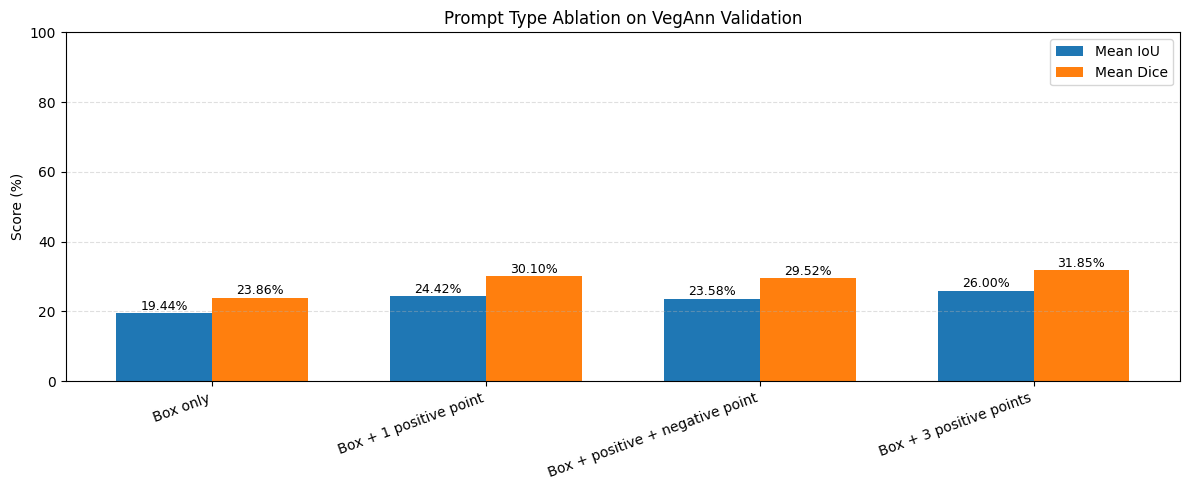

In [52]:
methods = prompt_ablation_df["Prompt Type"].tolist()
iou_scores = [x * 100 for x in prompt_ablation_df["Mean IoU"].tolist()]
dice_scores = [x * 100 for x in prompt_ablation_df["Mean Dice"].tolist()]

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    iou_scores,
    width,
    label="Mean IoU"
)

plt.bar(
    x + width / 2,
    dice_scores,
    width,
    label="Mean Dice"
)

plt.xticks(
    x,
    methods,
    rotation=20,
    ha="right"
)

plt.ylabel("Score (%)")
plt.title("Prompt Type Ablation on VegAnn Validation")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(iou_scores):
    plt.text(
        i - width / 2,
        v + 1,
        f"{v:.2f}%",
        ha="center",
        fontsize=9
    )

for i, v in enumerate(dice_scores):
    plt.text(
        i + width / 2,
        v + 1,
        f"{v:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "prompt_type_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
prompt_ablation_df.to_csv(
    "prompt_type_ablation_results.csv",
    index=False
)

prompt_ablation_percent.to_csv(
    "prompt_type_ablation_results_percent.csv",
    index=False
)

print("Prompt ablation results saved.")

Prompt ablation results saved.
